In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

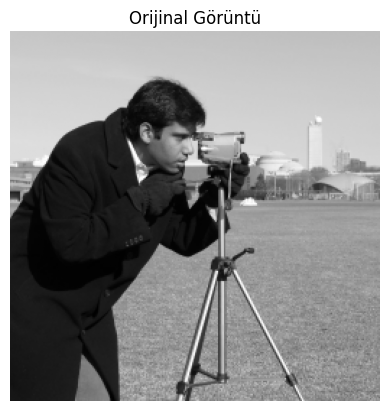

In [3]:
resim = cv2.imread(
    "image11.png",
    cv2.IMREAD_GRAYSCALE
)

resim = cv2.resize(resim, (256, 256))

plt.imshow(resim, cmap="gray")
plt.title("Orijinal Görüntü")
plt.axis("off")
plt.show()

In [5]:
def gauss_gurultusu(goruntu, sigma):
    gurultu = np.random.normal(0, sigma, goruntu.shape)
    sonuc = goruntu.astype(float) + gurultu
    return np.clip(sonuc, 0, 255).astype(np.uint8)


def salt_pepper_gurultusu(goruntu, oran):
    if not 0 <= oran <= 1:
        raise ValueError("Oran 0 ile 1 arasında olmalı!")

    sonuc = goruntu.copy()
    adet = int(sonuc.size * oran)

    indeksler = np.random.choice(
        sonuc.size, adet, replace=False
    )

    duz = sonuc.ravel()
    yari = adet // 2

    duz[indeksler[:yari]] = 0
    duz[indeksler[yari:]] = 255

    return sonuc

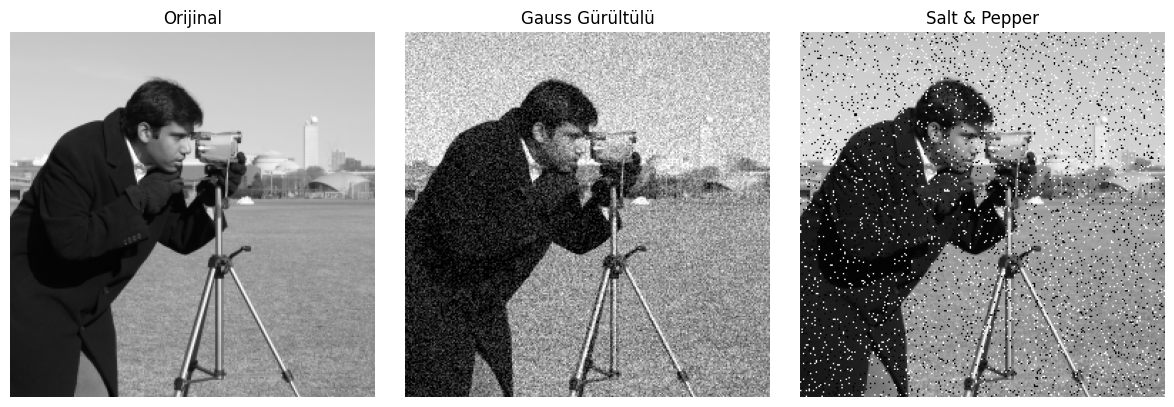

In [6]:
np.random.seed(42)

gauss_resim = gauss_gurultusu(resim, 25)
sp_resim = salt_pepper_gurultusu(resim, 0.08)

goruntuler = {
    "Orijinal": resim,
    "Gauss Gürültülü": gauss_resim,
    "Salt & Pepper": sp_resim
}

plt.figure(figsize=(12, 4))

for i, (ad, goruntu) in enumerate(goruntuler.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(goruntu, cmap="gray", vmin=0, vmax=255)
    plt.title(ad)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
def filtreleri_olustur(boyut, kesim=0.10, alt=0.05, ust=0.20):
    h, w = boyut

    fy = np.fft.fftfreq(h)
    fx = np.fft.fftfreq(w)

    D = np.sqrt(fy[:, None]**2 + fx[None, :]**2)

    low_pass = np.exp(-(D**2) / (2 * kesim**2))

    high_pass = 1 - low_pass

    band_pass = (
        np.exp(-(D**2) / (2 * ust**2))
        - np.exp(-(D**2) / (2 * alt**2))
    )

    band_reject = 1 - band_pass

    return {
        "Low-Pass": low_pass,
        "High-Pass": high_pass,
        "Band-Pass": band_pass,
        "Band-Reject": band_reject
    }


maskeler = filtreleri_olustur(resim.shape)

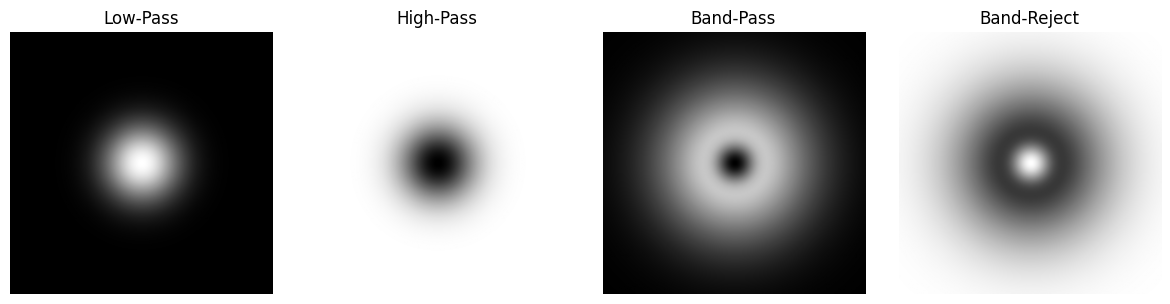

In [8]:
plt.figure(figsize=(12, 3))

for i, (ad, maske) in enumerate(maskeler.items()):
    plt.subplot(1, 4, i + 1)

    plt.imshow(
        np.fft.fftshift(maske),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(ad)
    plt.axis("off")

plt.tight_layout()
plt.savefig("odev40_filtre_maskeleri.png", dpi=200)
plt.show()

In [9]:
def frekans_filtrele(goruntu, maske):
    harmonik = np.fft.fft2(goruntu.astype(float))

    filtreli_harmonik = harmonik * maske

    sonuc = np.fft.ifft2(filtreli_harmonik)

    return sonuc.real

In [11]:
sonuclar = {}

for goruntu_adi, goruntu in goruntuler.items():

    sonuclar[goruntu_adi] = {}

    for filtre_adi, maske in maskeler.items():

        filtreli = frekans_filtrele(goruntu, maske)

        sonuclar[goruntu_adi][filtre_adi] = filtreli

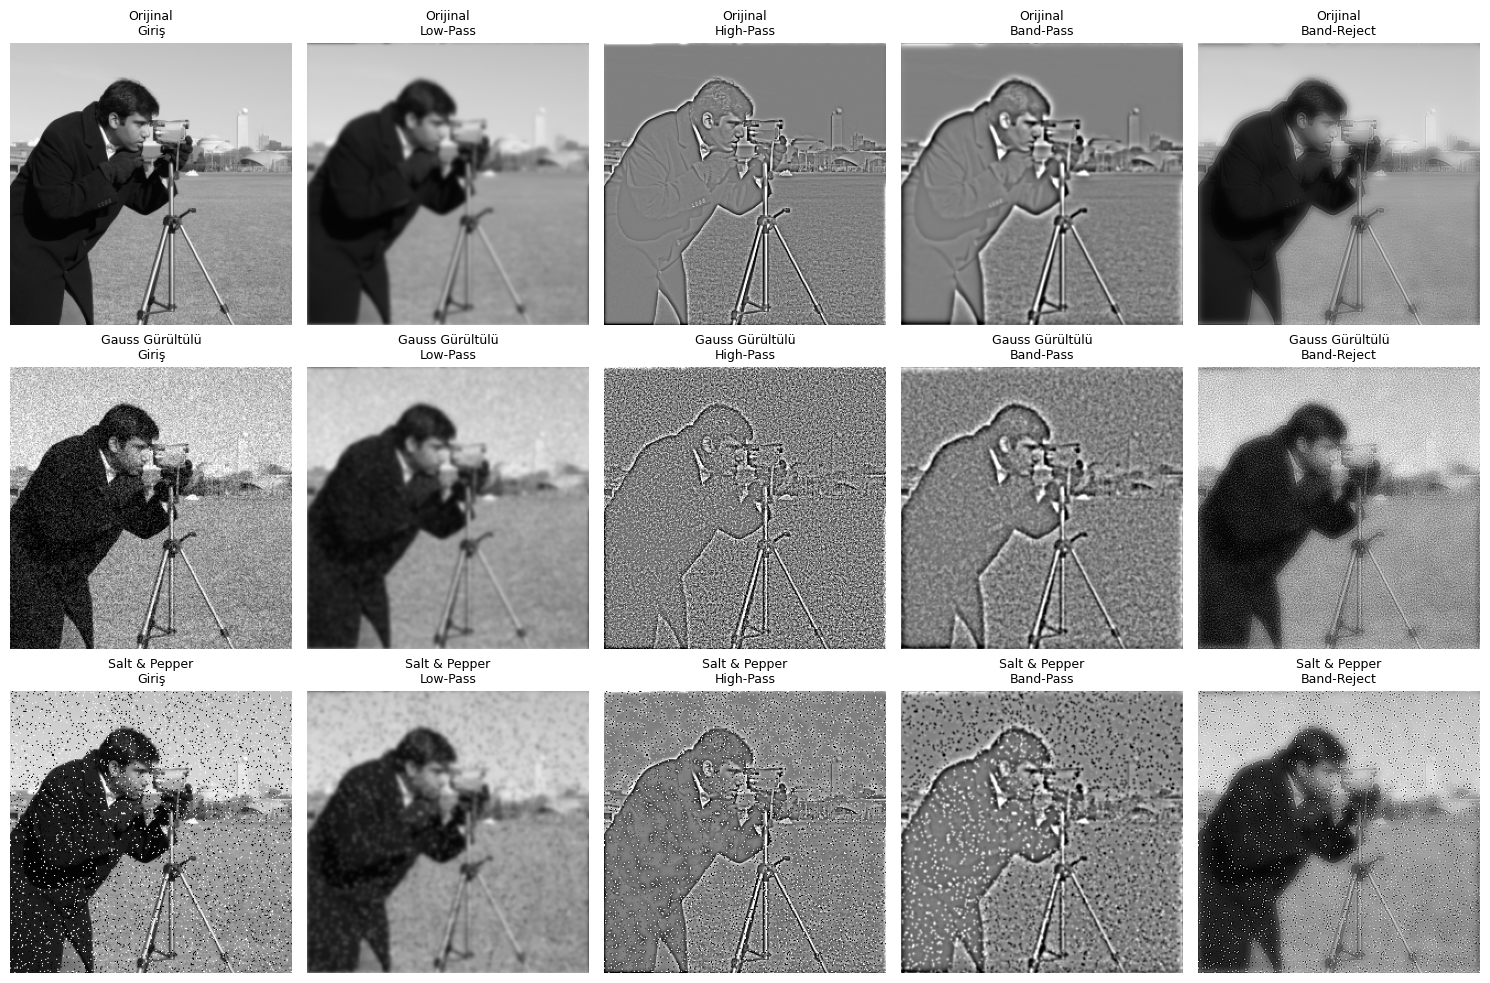

In [12]:
plt.figure(figsize=(15, 10))

for i, (goruntu_adi, goruntu) in enumerate(goruntuler.items()):

    resimler = [goruntu] + list(sonuclar[goruntu_adi].values())
    basliklar = ["Giriş"] + list(maskeler.keys())

    for j in range(5):

        plt.subplot(3, 5, i * 5 + j + 1)

        if j in [2, 3]:
            goster = np.clip(128 + 2 * resimler[j], 0, 255)
        else:
            goster = np.clip(resimler[j], 0, 255)

        plt.imshow(goster, cmap="gray", vmin=0, vmax=255)
        plt.title(f"{goruntu_adi}\n{basliklar[j]}", fontsize=9)
        plt.axis("off")

plt.tight_layout()
plt.savefig("odev40_filtre_sonuclari.png", dpi=200)
plt.show()

In [13]:
def kenar_gucu(goruntu):
    g = goruntu.astype(np.float32)

    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)

    return np.mean(np.sqrt(gx**2 + gy**2))


for ad, goruntu in goruntuler.items():

    print("\n", ad)
    print(f"{'Filtre':<15} {'Ort. Parlaklık':>15} {'Kenar Gücü':>15}")

    veriler = {"Giriş": goruntu.astype(float)}
    veriler.update(sonuclar[ad])

    for filtre_adi, sonuc in veriler.items():
        print(
            f"{filtre_adi:<15} "
            f"{np.mean(sonuc):>15.2f} "
            f"{kenar_gucu(sonuc):>15.2f}"
        )


 Orijinal
Filtre           Ort. Parlaklık      Kenar Gücü
Giriş                    129.18           56.51
Low-Pass                 129.18           29.95
High-Pass                  0.00           45.48
Band-Pass                 -0.00           36.87
Band-Reject              129.18           34.75

 Gauss Gürültülü
Filtre           Ort. Parlaklık      Kenar Gücü
Giriş                    129.42          130.50
Low-Pass                 129.42           37.57
High-Pass                  0.00          114.97
Band-Pass                 -0.00           64.20
Band-Reject              129.42           80.88

 Salt & Pepper
Filtre           Ort. Parlaklık      Kenar Gücü
Giriş                    128.89          155.10
Low-Pass                 128.89           44.79
High-Pass                  0.00          144.30
Band-Pass                  0.00           82.55
Band-Reject              128.89          105.47
